<h1>CME538 - Introduction to Data Science</h1><h2>Lecture 7.3 - Cross-Validation and Class Imbalance</h2><p>Lecture 7.2 used validation data to choose decisions. We now protect a final test, repeat validation across sensible folds, and examine what changes when positives are rare. Central question: How do we choose a useful classifier without overstating its performance?</p><p>You will separate development from final testing, choose suitable folds, and compare strategies for rare outcomes.</p><h3>Lecture Structure</h3><ol><li><a href="#section1">Train-Validation-Test Split</a></li><li><a href="#section2">K-Fold Cross-Validation</a></li><li><a href="#section3">Structured Cross-Validation</a></li><li><a href="#section4">Class Imbalance</a></li><li><a href="#section5">Managing Class Imbalance</a></li></ol><p><a href="#summary">Lecture summary</a></p><h3>Sources and documentation</h3><p><a href="DATA_SOURCES.md">Data descriptions and attribution</a>. <a href="https://scikit-learn.org/stable/modules/cross_validation.html">Scikit-learn cross-validation</a>. <a href="https://imbalanced-learn.org/stable/common_pitfalls.html">Resampling and leakage</a>. <a href="https://scikit-learn.org/stable/modules/classification_threshold.html">Decision-threshold tuning</a>.</p>

<h2>Setup Notebook</h2><p>Run the prepared cells in order in the course environment. The <a href="requirements.txt">dependency list</a> records the required packages. All examples use local data. Scikit-learn provides the splitters, pipelines, classifiers and metrics. RandomOverSampler and RandomUnderSampler come from imbalanced-learn, a companion library that follows the scikit-learn API. Its pipeline resamples training folds while leaving validation and test rows intact. The threshold-tuning example requires scikit-learn 1.5 or later. Plot layout and display helpers live in <code>utils.py</code>.</p>

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (
    train_test_split, KFold, ShuffleSplit, LeaveOneOut, GroupKFold,
    StratifiedGroupKFold, TimeSeriesSplit, cross_val_score, cross_validate,
    TunedThresholdClassifierCV,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, balanced_accuracy_score
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import make_pipeline as make_sampling_pipeline
import utils

RANDOM_STATE = 538
utils.configure_plots()

<a id="section1"></a><h2>1. Train-Validation-Test Split</h2><p>Question: How do we compare choices without using the final test to make them?</p>

<h3>1.1 Name the observation and the target</h3><p>The NBA file contains one team row per completed game. Two rows from the same game are dependent. We classify wins retrospectively from shooting, rebounding and other box-score statistics. Scores and final margin are excluded as features because they directly reveal the outcome. The random game split evaluates other completed games from the same data source. Forecasting future games would require features available before play and a chronological evaluation.</p>

In [2]:
nba = pd.read_csv('nba.csv')
features = ['FG_PCT', 'FG3_PCT', 'FT_PCT', 'OREB', 'DREB',
            'AST', 'STL', 'BLK', 'TOV', 'PF']
X = nba[features]
y = (nba.WL == 'W').astype(int)
groups = nba.GAME_ID
display(nba[['GAME_ID', 'GAME_DATE', 'TEAM_ABBREVIATION', 'WL']].head())
print('Win fraction:', y.mean())

,GAME_ID,GAME_DATE,TEAM_ABBREVIATION,WL
0,21700002,2017-10-17,GSW,L
1,21700002,2017-10-17,HOU,W
2,21700001,2017-10-17,BOS,L
3,21700001,2017-10-17,CLE,W
4,21700011,2017-10-18,MIN,L


Win fraction: 0.5


<h3>1.2 Assign three roles</h3><p>Training fits parameters. Validation compares choices. Together, training and validation form the development data. The test set estimates performance after the choices are fixed. Split the unique games first, then retrieve both team rows. The slides illustrate a 70/15/15 split. Here we use 60% of games for training, 20% for validation and 20% for testing. Both choices assign the same three roles.</p>

In [3]:
dev_ids, test_ids = train_test_split(groups.unique(), test_size=0.20, random_state=RANDOM_STATE)
train_ids, val_ids = train_test_split(dev_ids, test_size=0.25, random_state=RANDOM_STATE)
train_mask = groups.isin(train_ids)
val_mask = groups.isin(val_ids)
dev_mask = groups.isin(dev_ids)
test_mask = groups.isin(test_ids)
assert set(train_ids).isdisjoint(val_ids)
assert set(dev_ids).isdisjoint(test_ids)
print('Training / validation / test rows:', train_mask.sum(), val_mask.sum(), test_mask.sum())

Training / validation / test rows: 1476 492 492


<h3>1.3 Fit preprocessing on training rows</h3><p>A pipeline fits the scaler and classifier together. Its validation predictions use the training means and standard deviations. When cross-validation refits the pipeline, the scaler is refitted using each training fold.</p>

In [4]:
pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
pipeline.fit(X.loc[train_mask], y.loc[train_mask])
validation_prediction = pipeline.predict(X.loc[val_mask])
print('Validation accuracy:', round(accuracy_score(y.loc[val_mask], validation_prediction), 3))

Validation accuracy: 0.825


<p>Takeaway: Assign the test set before comparing models. Keep related game rows together and learn preprocessing only from the rows used for fitting. Next, rotate the validation games to compare choices across several splits.</p>

<a id="section2"></a><h2>2. K-Fold Cross-Validation</h2><p>Question: How sensitive is the result to one particular validation split?</p>

<h3>2.1 Rotate the validation games</h3><p>Five-fold cross-validation fits five separate models. Each fit holds out a different fifth of the development games. GroupKFold keeps each game together. The test games remain excluded.</p>

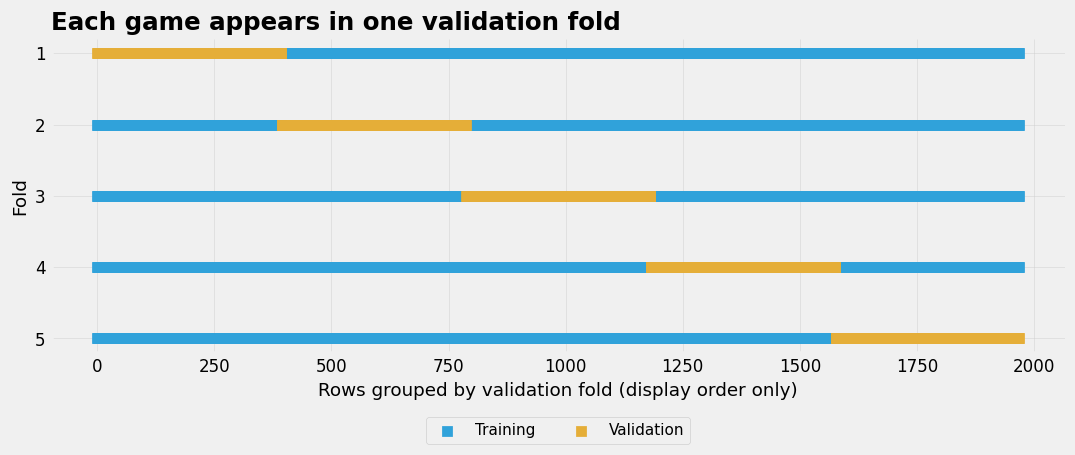

In [5]:
X_dev, y_dev = X.loc[dev_mask], y.loc[dev_mask]
dev_groups = groups.loc[dev_mask]
cv = GroupKFold(n_splits=5)
folds = list(cv.split(X_dev, y_dev, groups=dev_groups))
for training_rows, validation_rows in folds:
    assert set(dev_groups.iloc[training_rows]).isdisjoint(dev_groups.iloc[validation_rows])
utils.split_plot(folds, len(X_dev), 'Each game appears in one validation fold')

Fold accuracies: [0.853 0.802 0.759 0.832 0.821]
Mean / standard deviation: 0.814 0.036


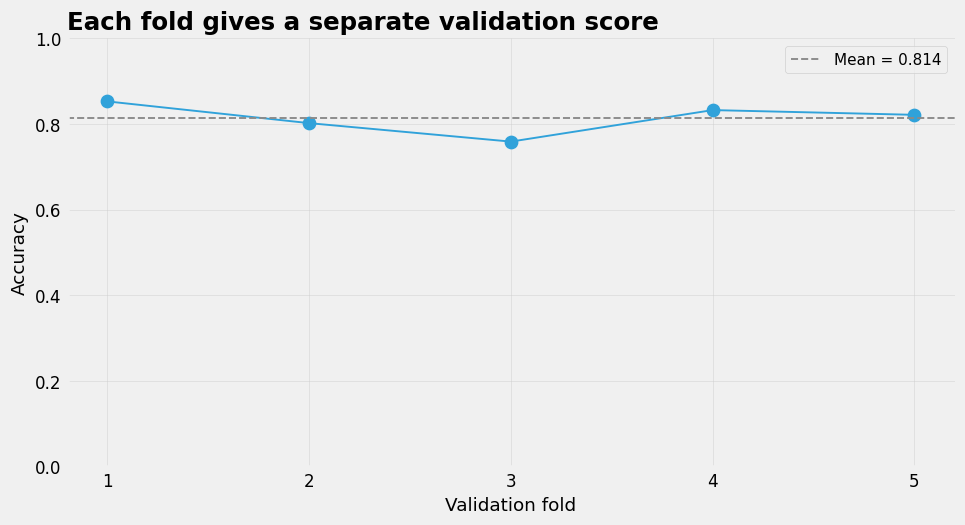

In [6]:
fold_accuracy = cross_val_score(
    pipeline, X_dev, y_dev, cv=cv, groups=dev_groups, scoring='accuracy'
)
print('Fold accuracies:', fold_accuracy.round(3))
print('Mean / standard deviation:', fold_accuracy.mean().round(3), fold_accuracy.std(ddof=1).round(3))
utils.cv_scores(fold_accuracy)

<p>These are five validation scores, not five scores from the final test. Their spread reveals sensitivity to the held-out games; it is not a confidence interval. Investigate an unusually weak fold for a meaningful population difference, errors or leakage rather than deleting it.</p>

<h3>2.2 Compare feature choices</h3><p>Use the same folds to compare shooting features alone with the wider box score. We select the feature set with higher mean validation accuracy. The selection rule is fixed before inspecting the final test.</p>

In [7]:
shooting_features = ['FG_PCT', 'FG3_PCT', 'FT_PCT']
shooting_scores = cross_val_score(
    pipeline, X_dev[shooting_features], y_dev, cv=folds, scoring='accuracy'
)
comparison = pd.DataFrame({
    'Shooting': shooting_scores,
    'Full box score': fold_accuracy,
})
display(comparison.agg(['mean', 'std']).round(3))
selected_features = (
    shooting_features if shooting_scores.mean() > fold_accuracy.mean() else features
)

,Shooting,Full box score
mean,0.688,0.814
std,0.025,0.036


<h3>2.3 Refit, then test once</h3><p>Fit the selected pipeline on all development games. Only now use the reserved test games. Repeatedly adjusting choices after seeing this score would turn these games into another validation set.</p>

In [8]:
final_win_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
final_win_model.fit(X_dev[selected_features], y_dev)
final_win_prediction = final_win_model.predict(X.loc[test_mask, selected_features])
print('Final win/loss test accuracy:', round(accuracy_score(y.loc[test_mask], final_win_prediction), 3))

Final win/loss test accuracy: 0.841


<h3>2.4 Use the other splitters from the slides</h3><p>For independent observations, KFold holds each row out once. ShuffleSplit makes repeated random holdouts. LeaveOneOut holds out one row per fit. Inspect the first split of each on six illustrative rows. Use one of these splitter objects as the <code>cv</code> argument to <code>cross_val_score</code> when its assumptions match the data. Our two-row-per-game data still require grouped folds.</p>

In [9]:
illustration_rows = np.arange(6).reshape(-1, 1)
splitters = {
    'KFold': KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    'ShuffleSplit': ShuffleSplit(n_splits=3, test_size=2, random_state=RANDOM_STATE),
    'LeaveOneOut': LeaveOneOut(),
}
for name, splitter in splitters.items():
    train_rows, validation_rows = next(splitter.split(illustration_rows))
    print(name, '| fits:', splitter.get_n_splits(illustration_rows),
          '| first training rows:', train_rows, '| first validation rows:', validation_rows)

KFold | fits: 3 | first training rows: [2 3 4 5] | first validation rows: [0 1]
ShuffleSplit | fits: 3 | first training rows: [4 3 2 5] | first validation rows: [0 1]
LeaveOneOut | fits: 6 | first training rows: [1 2 3 4 5] | first validation rows: [0]


<p>Takeaway: Cross-validation compares choices through repeated fitting. After selection, refit on the development data and evaluate once on the untouched test games. The next examples change the fold design to represent future observations and new locations.</p>

<a id="section3"></a><h2>3. Structured Cross-Validation</h2><p>Question: Which held-out observations represent the new cases we care about?</p>

<h3>3.1 Chronological validation</h3><p>Predicting later observations requires validation after training. A shuffled split can put later information in training. We demonstrate the split using one row per game from the development data, sorted by date.</p>

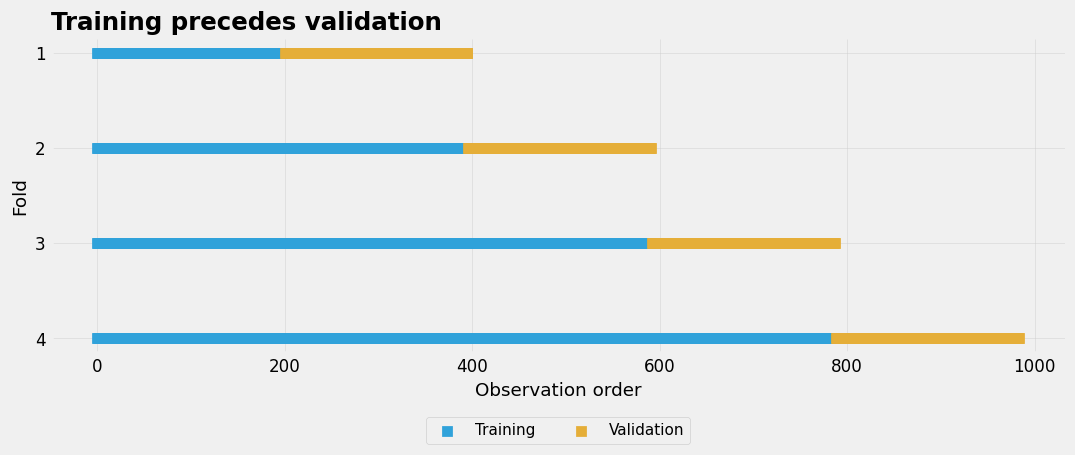

In [10]:
chronological = nba.loc[dev_mask].copy()
chronological['GAME_DATE'] = pd.to_datetime(chronological.GAME_DATE)
chronological = chronological.sort_values(['GAME_DATE', 'GAME_ID']).drop_duplicates('GAME_ID')
time_cv = TimeSeriesSplit(n_splits=4)
time_folds = list(time_cv.split(chronological))
utils.split_plot(time_folds, len(chronological), 'Training precedes validation')

<p>The diagram shows index order. For a deployment with many games on the same date, define fold boundaries by whole dates. Rolling features must use past information only. A gap may be needed when neighbouring observations remain dependent.</p>

<h3>3.2 Spatial validation with a simple sensor dataset</h3><p>Nearby sensors share local conditions. We generate 240 locations in four east–west regions. The label records whether a smooth, spatially varying quantity exceeds a threshold. A random split estimates performance among already sampled areas; holding out a region asks about a new area.</p><p>The neighbour classifier below assigns the majority label among the seven closest training sensors. It measures proximity using standardized coordinates. This makes the value of nearby examples visible.</p>

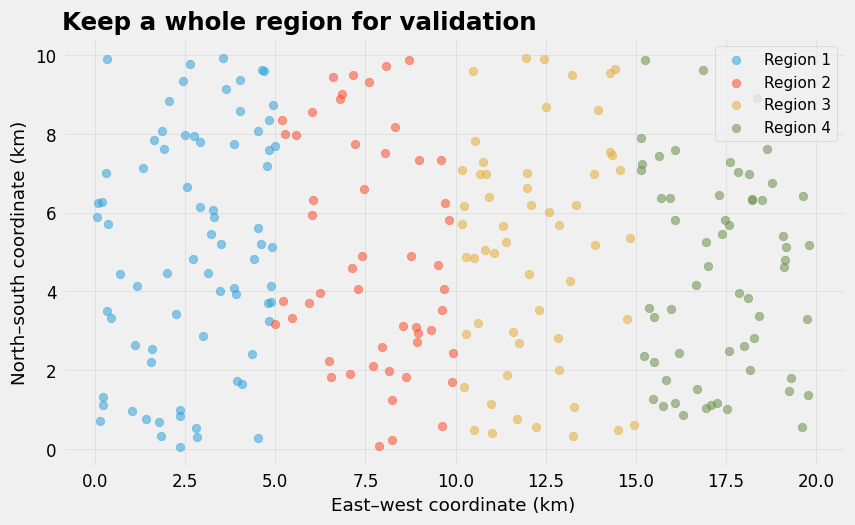

In [11]:
sensor_rng = np.random.default_rng(RANDOM_STATE)
east = sensor_rng.uniform(0, 20, 240)
north = sensor_rng.uniform(0, 10, 240)
region = np.minimum((east / 5).astype(int), 3)
local_signal = np.sin(east/2) + 0.6*np.cos(north/2)
sensor_label = (local_signal + sensor_rng.normal(0, 0.25, 240) > 0).astype(int)
sensor_X = pd.DataFrame({'East': east, 'North': north})
utils.spatial_folds(east, north, region)

In [12]:
spatial_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))
random_cv = KFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
region_cv = GroupKFold(n_splits=4)
random_scores = cross_val_score(spatial_model, sensor_X, sensor_label, cv=random_cv)
region_scores = cross_val_score(spatial_model, sensor_X, sensor_label, cv=region_cv, groups=region)
display(pd.DataFrame({'Random locations': random_scores, 'New region': region_scores}).round(3))
print('Mean accuracies:', random_scores.mean().round(3), region_scores.mean().round(3))

,Random locations,New region
0,0.883,0.554
1,0.833,0.667
2,0.850,0.927
3,0.883,0.706


Mean accuracies: 0.862 0.713


<p>The scores answer different questions. The new-region task requires extrapolation into a spatial gap, while random folds often leave nearby training sensors. Region geometry, environmental differences and spatial dependence can all contribute to the gap. This example does not estimate one isolated effect of autocorrelation.</p>

<h3>3.3 Groups are defined by the use case</h3><p>For a new patient, keep all of that patient’s records together. For a new mine site, keep its boreholes together. For a new game, keep the two team rows together. Ordinary shuffled folds are appropriate only when the intended new cases are sufficiently independent and exchangeable with the observed rows. Leave-one-out uses one validation observation per fit and can be costly; it does not solve dependence.</p>

<p>Takeaway: Choose folds to represent the intended new cases. Time, location and repeated observations determine which rows belong together. Once the split matches the question, choose metrics which reveal errors on the class of interest.</p>

<a id="section4"></a><h2>4. Class Imbalance</h2><p>Question: Why can high accuracy conceal failure on the class of interest?</p>

<h3>4.1 Create a genuinely rare outcome</h3><p>Win/loss is balanced in this file. For a separate task, class 1 now means winning by at least 20 points. This outcome is rare. We retain the same explanatory features and exclude final margin, which defines the target. Again, this is retrospective classification of completed games.</p>

In [13]:
rare_y = ((nba.WL == 'W') & (nba.PLUS_MINUS >= 20)).astype(int)
print('Positive fraction:', round(rare_y.mean(), 3))
display(rare_y.value_counts().rename(index={0: 'Other result', 1: '20+ point win'}))

Positive fraction: 0.068


Other result     2292
20+ point win     168
Name: count, dtype: int64

<h3>4.2 Stratify game groups</h3><p>A game-level indicator records whether a game contains a 20-point winner. Stratify those games so each split contains rare outcomes, then retrieve the team rows. Grouping prevents dependence across splits; stratification helps preserve class composition.</p>

In [14]:
game_rare = pd.DataFrame({'GAME_ID': groups, 'Rare': rare_y}).groupby('GAME_ID').Rare.max()
rare_dev_ids, rare_test_ids = train_test_split(game_rare.index, test_size=0.20,
    stratify=game_rare, random_state=RANDOM_STATE)
rare_train_ids, rare_val_ids = train_test_split(rare_dev_ids, test_size=0.25,
    stratify=game_rare.loc[rare_dev_ids], random_state=RANDOM_STATE)
rt = groups.isin(rare_train_ids)
rv = groups.isin(rare_val_ids)
rd = groups.isin(rare_dev_ids)
rtest = groups.isin(rare_test_ids)
assert set(rare_train_ids).isdisjoint(rare_val_ids)
assert set(rare_dev_ids).isdisjoint(rare_test_ids)

<h3>4.3 Compare with an always-negative baseline</h3><p>DummyClassifier provides the majority-class baseline. The classification_report function shows precision, recall, F1 and support (the number of actual observations) for each class, plus overall accuracy. Focus on the 20+ point win row: high accuracy does not require finding any of those wins.</p><p>Balanced accuracy averages recall across the two classes, giving each class equal weight. The always-negative baseline has recalls of 1 for other results and 0 for 20+ point wins, so its balanced accuracy is 0.50. Precision measures the fraction of positive predictions that are correct.</p><p>We set <code>zero_division=0</code> so a report prints 0 when precision has no predicted positives in its denominator. Precision is then mathematically undefined. The printed 0 is a reporting convention.</p>

In [15]:
class_names = ['Other result', '20+ point win']
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X.loc[rt], rare_y.loc[rt])
baseline_prediction = baseline.predict(X.loc[rv])
print(classification_report(
    rare_y.loc[rv], baseline_prediction, target_names=class_names, zero_division=0
))
print('Balanced accuracy:', balanced_accuracy_score(rare_y.loc[rv], baseline_prediction))

               precision    recall  f1-score   support

 Other result       0.93      1.00      0.96       458
20+ point win       0.00      0.00      0.00        34

     accuracy                           0.93       492
    macro avg       0.47      0.50      0.48       492
 weighted avg       0.87      0.93      0.90       492

Balanced accuracy: 0.5


<p>Now fit a logistic model and evaluate the same validation games with the same report. The positive-class row shows how many large wins the fitted model finds and how reliable its alerts are.</p>

In [16]:
plain_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
plain_model.fit(X.loc[rt], rare_y.loc[rt])
plain_prediction = plain_model.predict(X.loc[rv])
print(classification_report(
    rare_y.loc[rv], plain_prediction, target_names=class_names, zero_division=0
))
print('Balanced accuracy:', round(balanced_accuracy_score(rare_y.loc[rv], plain_prediction), 3))

               precision    recall  f1-score   support

 Other result       0.95      1.00      0.97       458
20+ point win       0.82      0.26      0.40        34

     accuracy                           0.95       492
    macro avg       0.88      0.63      0.69       492
 weighted avg       0.94      0.95      0.93       492

Balanced accuracy: 0.63


<p>In the confusion matrix, rows are actual classes and columns are predicted classes. The colour bar shows counts: darker blue means more observations. Diagonal cells are correct decisions; off-diagonal cells are mistakes.</p>

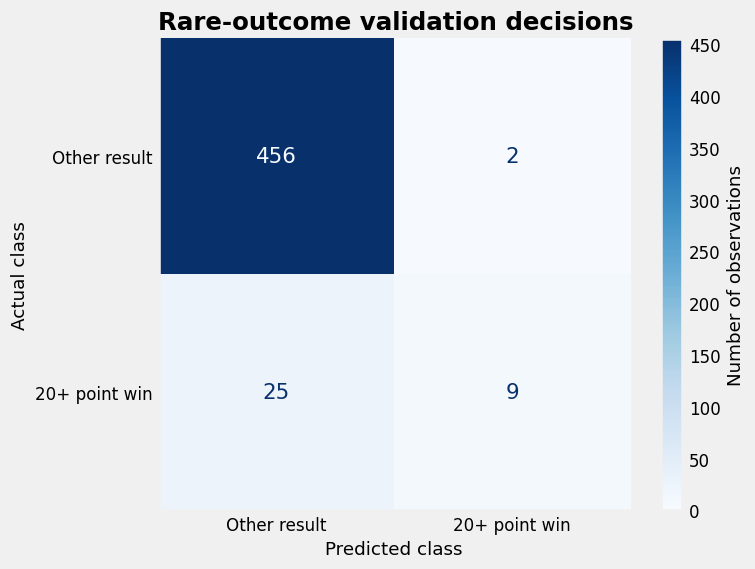

In [17]:
utils.confusion(rare_y.loc[rv], plain_model.predict(X.loc[rv]), 'Rare-outcome validation decisions')

<p>Takeaway: High accuracy does not guarantee success at finding rare positives. Use DummyClassifier as a baseline, then inspect the positive-class precision, recall and F1. Next, change the training procedure and compare the strategies using validation folds with the original class composition.</p>

<a id="section5"></a><h2>5. Managing Class Imbalance</h2><p>Question: Which changes help the rare class without contaminating evaluation?</p>

<h3>5.1 Weight the loss by class frequency</h3><p>Class weights multiply each observation’s contribution to the training loss. With <code>class_weight="balanced"</code>, scikit-learn sets the weight for class c to w<sub>c</sub> = n / (K × n<sub>c</sub>): n is the number of training rows, K is the number of classes, and n<sub>c</sub> is the number of training rows in class c. A rare class receives a larger weight.</p><p>Use compute_class_weight to see the weights for our training labels. The final column shows how each class contributes the same total weight, although their row counts differ.</p>

In [18]:
training_counts = rare_y.loc[rt].value_counts().sort_index()
weights = compute_class_weight(
    class_weight='balanced', classes=np.array([0, 1]), y=rare_y.loc[rt]
)
display(pd.DataFrame({
    'Training rows': training_counts,
    'Weight per row': weights,
    'Total weight': training_counts * weights,
}).rename(index={0: class_names[0], 1: class_names[1]}).round(3))

,Training rows,Weight per row,Total weight
Other result,1376,0.536,738.0
20+ point win,100,7.380,738.0


<p>Pass <code>class_weight="balanced"</code> to LogisticRegression to apply those weights. During cross-validation, each fitted model recomputes them from its training fold. For known relative costs, supply a dictionary such as <code>{0: 1, 1: 5}</code>. This gives each positive row five times the loss weight of a negative row. In this example, weighting raises recall and increases false positives. The resulting probability values need not be calibrated to the original population.</p>

In [19]:
weighted_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=2000),
)
weighted_model.fit(X.loc[rt], rare_y.loc[rt])
print(classification_report(
    rare_y.loc[rv], weighted_model.predict(X.loc[rv]),
    target_names=class_names, zero_division=0,
))

               precision    recall  f1-score   support

 Other result       0.98      0.82      0.89       458
20+ point win       0.24      0.74      0.36        34

     accuracy                           0.82       492
    macro avg       0.61      0.78      0.63       492
 weighted avg       0.93      0.82      0.86       492



<h3>5.2 Oversample and undersample with imbalanced-learn</h3><p>RandomOverSampler duplicates minority training rows. RandomUnderSampler removes majority training rows. Both expose <code>fit_resample(X, y)</code>. Compare their training class counts below. Neither operation adds independent evidence. Undersampling also discards information contained in the removed rows.</p>

In [20]:
over_sampler = RandomOverSampler(random_state=RANDOM_STATE)
under_sampler = RandomUnderSampler(random_state=RANDOM_STATE)
X_over, y_over = over_sampler.fit_resample(X.loc[rt], rare_y.loc[rt])
X_under, y_under = under_sampler.fit_resample(X.loc[rt], rare_y.loc[rt])
display(pd.DataFrame({
    'Original training': rare_y.loc[rt].value_counts(),
    'Oversampled training': y_over.value_counts(),
    'Undersampled training': y_under.value_counts(),
}).sort_index().rename(index={0: class_names[0], 1: class_names[1]}))

,Original training,Oversampled training,Undersampled training
Other result,1376,1376,100
20+ point win,100,1376,100


<p>For model fitting and cross-validation, put the sampler inside an imbalanced-learn pipeline. Each call to fit resamples its training rows, fits the scaler and fits the classifier. Prediction skips the sampler: validation and test rows keep their original distribution. Pass the original development rows to cross-validation, not X_over or X_under.</p>

In [21]:
over_model = make_sampling_pipeline(
    RandomOverSampler(random_state=RANDOM_STATE),
    StandardScaler(),
    LogisticRegression(max_iter=2000),
)
under_model = make_sampling_pipeline(
    RandomUnderSampler(random_state=RANDOM_STATE),
    StandardScaler(),
    LogisticRegression(max_iter=2000),
)

<p>The weighted model’s validation report shows the tradeoff between finding more rare wins and issuing more false alerts. Compare the four training strategies on the same folds next. The sampling pipelines will be fitted by cross_validate, which clones and fits a fresh pipeline in each fold. Additional independent minority observations provide evidence beyond the existing rows.</p>

<h3>5.3 Compare strategies with cross_validate</h3><p>StratifiedKFold aims to preserve class proportions for independent rows. Here use StratifiedGroupKFold: this splitter keeps each game together and seeks similar proportions across folds. Exact class proportions are not guaranteed when groups must remain intact. Create the folds from development games only.</p>

In [22]:
X_rare_dev = X.loc[rd]
y_rare_dev = rare_y.loc[rd]
rare_groups = groups.loc[rd]
rare_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rare_folds = list(rare_cv.split(X_rare_dev, y_rare_dev, groups=rare_groups))
for train_rows, validation_rows in rare_folds:
    assert set(rare_groups.iloc[train_rows]).isdisjoint(rare_groups.iloc[validation_rows])
print('Rare positives in each validation fold:',
      [int(y_rare_dev.iloc[validation_rows].sum()) for _, validation_rows in rare_folds])

Rare positives in each validation fold: [27, 27, 27, 26, 27]


<p>cross_val_score returns one metric. cross_validate returns several when given a list of scoring names. The scoring names below request the built-in metrics. We compare mean F1 at the default threshold of 0.5, with precision and recall alongside F1 to explain the tradeoff. F1 is our stated selection rule for this demonstration. Choose a rule based on the error costs of the decision.</p><p>The returned keys use names such as <code>test_f1</code>. Here <code>test_</code> means the held-out fold score, not a score on our reserved final test set.</p>

In [23]:
strategies = {
    'Plain': plain_model, 'Class weights': weighted_model,
    'Oversampling': over_model, 'Undersampling': under_model,
}
scoring = ['accuracy', 'precision', 'recall', 'f1', 'balanced_accuracy']
strategy_scores = {}
for name, model in strategies.items():
    scores = cross_validate(model, X_rare_dev, y_rare_dev, cv=rare_folds, scoring=scoring)
    strategy_scores[name] = pd.DataFrame(scores).filter(like='test_').mean()
strategy_comparison = pd.DataFrame(strategy_scores).T
display(strategy_comparison.rename(columns=lambda name: name.removeprefix('test_')).round(3))
selected_strategy = strategy_comparison['test_f1'].idxmax()
print('Selected strategy:', selected_strategy)

,accuracy,precision,recall,f1,balanced_accuracy
Plain,0.944,0.699,0.328,0.441,0.659
Class weights,0.829,0.262,0.814,0.395,0.822
Oversampling,0.829,0.262,0.821,0.397,0.825
Undersampling,0.805,0.239,0.836,0.371,0.819


Selected strategy: Plain


<p>At threshold 0.5, the plain model has the highest mean F1, so our rule selects Plain. Class weighting raises mean recall from 0.33 to 0.81 while reducing precision from 0.70 to 0.26. Balancing the training classes does not automatically improve the chosen metric. We next tune the threshold for the selected strategy.</p>

<h3>5.4 Tune the threshold with scikit-learn</h3><p>TunedThresholdClassifierCV selects a decision threshold using validation predictions. Give it the chosen pipeline, the same grouped folds and <code>scoring="f1"</code>. The estimator fits on each training fold, searches thresholds on the held-out predictions, and refits the chosen pipeline on all development rows. Its predict method then applies the selected threshold.</p><p>LogisticRegression still minimizes cross-entropy, weighted where specified. F1 selects the threshold using validation predictions. The logistic fit minimizes cross-entropy. Scikit-learn’s LogisticRegression does not accept a custom soft-F1 training loss. Both strategy and threshold selection adapt to these validation folds. Their best score is therefore an optimistic estimate of future performance. Use the untouched test set for the final estimate.</p>

In [24]:
final_rare_model = TunedThresholdClassifierCV(
    estimator=strategies[selected_strategy],
    scoring='f1',
    cv=rare_folds,
    thresholds=101,
)
final_rare_model.fit(X_rare_dev, y_rare_dev)
print('Selected strategy:', selected_strategy)
print('Selected threshold:', round(final_rare_model.best_threshold_, 3))
print('Mean validation F1 at this threshold:', round(final_rare_model.best_score_, 3))

Selected strategy: Plain
Selected threshold: 0.355
Mean validation F1 at this threshold: 0.532


<h3>5.5 Evaluate the selected procedure once</h3><p>The test games have not been used to choose the training strategy or threshold. Call predict on those original rows, then use the same classification report.</p>

In [25]:
rare_test_prediction = final_rare_model.predict(X.loc[rtest])
print(classification_report(
    rare_y.loc[rtest], rare_test_prediction, target_names=class_names, zero_division=0
))
print('Test balanced accuracy:',
      round(balanced_accuracy_score(rare_y.loc[rtest], rare_test_prediction), 3))

               precision    recall  f1-score   support

 Other result       0.96      0.98      0.97       458
20+ point win       0.60      0.44      0.51        34

     accuracy                           0.94       492
    macro avg       0.78      0.71      0.74       492
 weighted avg       0.93      0.94      0.94       492

Test balanced accuracy: 0.71


<p>This test score is the final estimate for the selected rare-outcome strategy. It may be lower than the best validation score because the choices were adapted to validation data. The win/loss task earlier and the rare-outcome task here are separate worked analyses.</p>

<p>Takeaway: Use class_weight to change the loss contributions, sampler pipelines to change training composition, and TunedThresholdClassifierCV to change the decision cutoff. Compare choices with validation data at its original prevalence, then test the selected procedure once.</p>

<a id="summary"></a><h2>Lecture summary</h2><ul><li>Training fits parameters; validation makes choices; the test is the final check.</li><li>Cross-validation repeats the full fitting process, including preprocessing.</li><li>Choose time, spatial or group splits to match the new cases of interest.</li><li>Rare positives make accuracy alone inadequate.</li><li>Choose a strategy and operating point from the decision costs and capacity, then evaluate honestly.</li></ul>